# IADS5 · TP integrador — Ortelana Textil
### Actividad 08 · Diagnóstico de generalización

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 08 · Diagnóstico de generalización

**Qué se espera:** Construí curvas de aprendizaje para árbol y ensamble; explorá train y CV al variar max_depth de 1 a 15 en el árbol. Proponé dos medidas para corregir el diagnóstico.

**Evidencia a entregar:** Curvas, diagnóstico de overfitting/underfitting y propuestas.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, learning_curve, validation_curve

cat_cols = ["Sucursal_ID", "Tela_ID"]          # identificadores: van con one-hot
num_cols = ["Año", "Metros1", "Metros2"]

def crear_pipeline(modelo):
    """One-hot para los identificadores y numéricas sin cambios (los árboles no necesitan escalado)."""
    preprocesador = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", "passthrough", num_cols),
    ], verbose_feature_names_out=False)   # nombres de columnas cortos, p. ej. "Tela_ID_TELA-001"
    return Pipeline([("prep", preprocesador), ("modelo", modelo)])

arbol = crear_pipeline(DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE))
rf = crear_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))

Árbol gini (depth=4)


,n_train,train,validación,brecha
0,210,0.7049,0.5425,0.1623
1,480,0.6884,0.6223,0.0661
2,750,0.6615,0.6069,0.0545
3,1020,0.6518,0.6086,0.0433
4,1291,0.6543,0.6091,0.0453
5,1561,0.6410,0.6044,0.0366
6,1831,0.6435,0.6170,0.0265
7,2102,0.6480,0.6257,0.0223


Random Forest (100)


,n_train,train,validación,brecha
0,210,1.0,0.6926,0.3074
1,480,1.0,0.8081,0.1919
2,750,1.0,0.8742,0.1258
3,1020,1.0,0.9065,0.0935
4,1291,1.0,0.9300,0.0700
5,1561,1.0,0.9492,0.0508
6,1831,1.0,0.9548,0.0452
7,2102,1.0,0.9632,0.0368


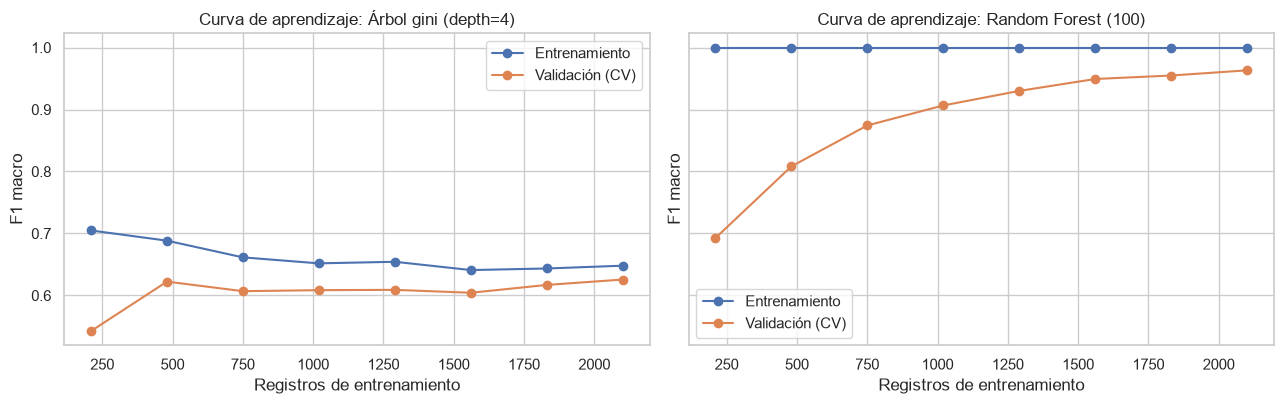

In [3]:
# 8.1 Curvas de aprendizaje: árbol (depth=4) y Random Forest
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tamanios = np.linspace(0.1, 1.0, 8)   # del 10% al 100% del train de cada fold

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, nombre, modelo in [(axes[0], "Árbol gini (depth=4)", arbol), (axes[1], "Random Forest (100)", rf)]:
    n, scores_train, scores_val = learning_curve(modelo, X_train, y_train, cv=cv5, scoring="f1_macro",
                                                 train_sizes=tamanios, n_jobs=-1, shuffle=True,
                                                 random_state=RANDOM_STATE)
    ax.plot(n, scores_train.mean(axis=1), "o-", label="Entrenamiento")
    ax.plot(n, scores_val.mean(axis=1), "o-", label="Validación (CV)")
    ax.set(title=f"Curva de aprendizaje: {nombre}", xlabel="Registros de entrenamiento", ylabel="F1 macro")
    ax.legend()

    print(nombre)
    display(pd.DataFrame({"n_train": n,
                          "train": scores_train.mean(axis=1),
                          "validación": scores_val.mean(axis=1),
                          "brecha": scores_train.mean(axis=1) - scores_val.mean(axis=1)}).round(4))
plt.tight_layout()
plt.show()

,train,CV media,CV desvío,brecha
max_depth,,,,
1,0.2968,0.2964,0.0074,0.0004
2,0.5166,0.4971,0.0229,0.0194
3,0.5316,0.5046,0.0265,0.0270
4,0.6484,0.6240,0.0303,0.0244
5,0.6836,0.6550,0.0260,0.0286
6,0.7458,0.7100,0.0317,0.0358
7,0.7905,0.7566,0.0330,0.0339
8,0.8317,0.7888,0.0331,0.0429
9,0.8639,0.8216,0.0336,0.0422


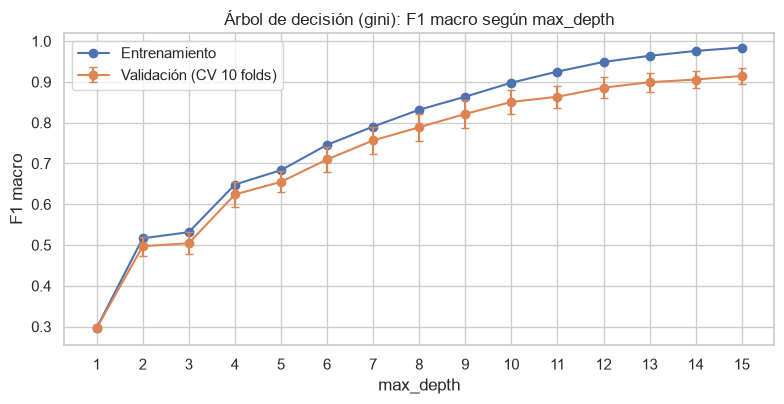

In [4]:
# 8.2 Curva de validación: árbol con max_depth de 1 a 15 (train vs. CV de 10 folds)
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
profundidades = np.arange(1, 16)

scores_train, scores_val = validation_curve(arbol, X_train, y_train, param_name="modelo__max_depth",
                                            param_range=profundidades, cv=cv10, scoring="f1_macro", n_jobs=-1)

curva = pd.DataFrame({"train": scores_train.mean(axis=1),
                      "CV media": scores_val.mean(axis=1),
                      "CV desvío": scores_val.std(axis=1),
                      "brecha": scores_train.mean(axis=1) - scores_val.mean(axis=1)},
                     index=pd.Index(profundidades, name="max_depth"))
display(curva.round(4))

plt.figure(figsize=(8, 4.2))
plt.plot(profundidades, curva["train"], "o-", label="Entrenamiento")
plt.errorbar(profundidades, curva["CV media"], yerr=curva["CV desvío"], fmt="o-", capsize=3,
             label="Validación (CV 10 folds)")
plt.title("Árbol de decisión (gini): F1 macro según max_depth")
plt.xlabel("max_depth")
plt.ylabel("F1 macro")
plt.xticks(profundidades)
plt.legend()
plt.tight_layout()
plt.show()

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Curvas de aprendizaje:** con `learning_curve`, CV estratificada de 5 folds y 8 tamaños de entrenamiento (del 10% al 100% del train de cada fold), para el árbol depth 4 y para el Random Forest, que es el mejor ensamble.
- **Curva de validación:** con `validation_curve`, `max_depth` de 1 a 15 y la misma CV de 10 folds de la Actividad 07.
- **Bandas:** todas las curvas muestran media ± desvío.

**Interpretación de los resultados:**
- **Árbol depth 4:** train y validación convergen rápido en torno a ~0,65 y ~0,63, con una brecha de 0,02 al usar todo el train, y más datos no mejoran el resultado. Es **underfitting (alto sesgo)**: el modelo es demasiado simple.
- **Random Forest:**
  - Train siempre vale 1,0 y la validación sube de 0,69 (210 filas) a 0,963 (2.102 filas).
  - La brecha baja de 0,31 a 0,04 y sigue achicándose.
  - Es un modelo de **varianza alta que se controla con más datos**. La curva todavía no se aplanó, así que más datos podrían ayudar.
- **Curva de profundidad:**
  - El F1 de CV sube de forma monótona de 0,30 (depth 1) a 0,915 (depth 15).
  - La brecha train–CV crece de ~0,02 (depth ≤ 4) a ~0,07 (depth ≥ 13), con train en 0,98.

**Pregunta de análisis:** ¿Dónde se abre una brecha entre entrenamiento y validación? ¿Más complejidad siempre ayuda?
- **Dónde se abre la brecha:**
  - En el árbol, a partir de depth ≈ 8: la brecha supera 0,04 y desde depth 11 queda en ~0,06–0,07.
  - En RF, con pocos datos: con 210 filas la brecha es de 0,31.
- **¿Más complejidad siempre ayuda?** No. Acá la validación sigue subiendo hasta depth 15 porque los cortes profundos aíslan pares (Sucursal, Tela) que se repiten en validación, pero la ganancia por nivel se achica (+0,03 de 10 a 12, +0,015 de 13 a 15) mientras la brecha crece.
  - Más complejidad ayuda mientras reduce el sesgo más de lo que aumenta la varianza.
- **Dos medidas para corregir el diagnóstico:**
  1. **Para el árbol, que tiene underfitting:** aumentar la capacidad de forma controlada, eligiendo `max_depth` por CV en el rango 8–15 junto con `min_samples_leaf` o `ccp_alpha` (poda por costo-complejidad) para no memorizar.
  2. **Para RF, que tiene alta varianza:** regularizar los árboles del bosque (`min_samples_leaf`, `max_depth`, `max_features`), evaluado con GridSearchCV como en la Actividad 14, o sumar más datos, porque la curva todavía no se estabilizó.

**Limitaciones o mejoras posibles:**
- Las curvas usan CV aleatoria: miden generalización a otros años de los mismos pares. Una curva con `GroupKFold` por par mostraría la brecha real ante pares nuevos.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
